# JS11 [Klasifikasi 2]: Support Vector Machine (SVM)
**Nama:** Sharren Elvaretta

**Kelas:** TI-3G

**NIM:** 244107020191

## Persiapan: Import Library, Load Data, dan Pra-Pengolahan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
FILE = 'lettuce_dataset_training_fix.csv'
if not os.path.exists(FILE):
    from google.colab import files
    files.upload()

Saving lettuce_dataset_training_fix.csv to lettuce_dataset_training_fix.csv


File CSV ini **tidak punya header** (baris pertama sudah berisi data), jadi nama kolom diberikan manual saat `read_csv`.

In [3]:
cols = ['Plant_ID', 'Date', 'Temp_C', 'Humidity', 'TDS', 'pH',
        'Growth_Days', 'Temp_F', 'Humidity_dec']
df = pd.read_csv(FILE, header=None, names=cols)

print(df.shape)
df.head()

(2213, 9)


,Plant_ID,Date,Temp_C,Humidity,TDS,pH,Growth_Days,Temp_F,Humidity_dec
0,22,8/3/2023,33.4,70,620,6.2,1,92.12,0.70
1,22,8/4/2023,33.5,63,800,6.5,2,92.30,0.63
2,22,8/5/2023,33.4,50,602,6.0,3,92.12,0.50
3,22,8/6/2023,33.4,50,721,6.0,4,92.12,0.50
4,22,8/7/2023,33.4,65,571,6.3,5,92.12,0.65


In [4]:
df.info()
print(df.isnull().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2213 entries, 0 to 2212
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Plant_ID      2213 non-null   int64  
 1   Date          2213 non-null   object 
 2   Temp_C        2213 non-null   float64
 3   Humidity      2213 non-null   int64  
 4   TDS           2213 non-null   int64  
 5   pH            2213 non-null   float64
 6   Growth_Days   2213 non-null   int64  
 7   Temp_F        2213 non-null   float64
 8   Humidity_dec  2213 non-null   float64
dtypes: float64(4), int64(4), object(1)
memory usage: 155.7+ KB
Plant_ID        0
Date            0
Temp_C          0
Humidity        0
TDS             0
pH              0
Growth_Days     0
Temp_F          0
Humidity_dec    0
dtype: int64


,Plant_ID,Temp_C,Humidity,TDS,pH,Growth_Days,Temp_F,Humidity_dec
count,2213.000000,2213.000000,2213.000000,2213.000000,2213.000000,2213.000000,2213.000000,2213.000000
mean,46.019431,27.067510,64.755535,598.870312,6.398373,23.084953,80.721518,0.647555
std,14.143353,5.004695,9.035112,116.838267,0.234554,13.043189,9.008450,0.090351
min,22.000000,18.000000,50.000000,400.000000,6.000000,1.000000,64.400000,0.500000
25%,34.000000,22.200000,57.000000,497.000000,6.200000,12.000000,71.960000,0.570000
50%,46.000000,29.800000,65.000000,593.000000,6.400000,23.000000,85.640000,0.650000
75%,58.000000,31.300000,73.000000,702.000000,6.600000,34.000000,88.340000,0.730000
max,70.000000,33.500000,80.000000,800.000000,6.800000,48.000000,92.300000,0.800000


**Penentuan fitur dan label**

- **Fitur:** `Temp_C`, `Humidity`, `TDS`, `pH` (data sensor lingkungan).
- Kolom `Temp_F` dan `Humidity_dec` dibuang karena hanya konversi satuan dari `Temp_C` dan `Humidity` (isinya sama).
- Kolom `Plant_ID` dan `Date` dibuang karena hanya identitas/waktu.
- **Label (`Fase`):** dataset tidak punya kolom kelas, jadi dibuat dari `Growth_Days`:
  `0` = fase awal (hari 1–24), `1` = fase akhir (hari 25–48).

Fase
0    1176
1    1037
Name: count, dtype: int64


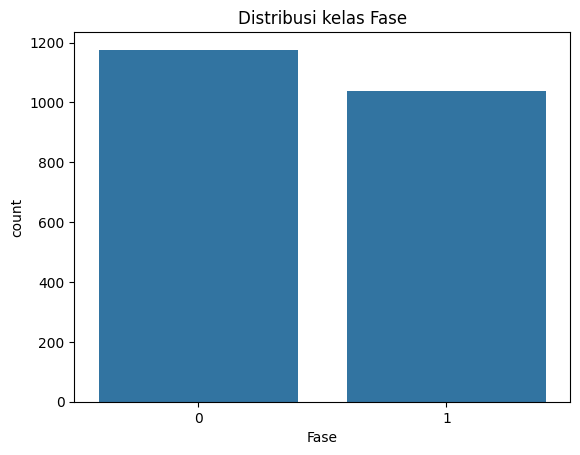

In [5]:
df['Fase'] = (df['Growth_Days'] > 24).astype(int)

fitur = ['Temp_C', 'Humidity', 'TDS', 'pH']
X = df[fitur]
y = df['Fase']

print(y.value_counts())
sns.countplot(x=y)
plt.title('Distribusi kelas Fase')
plt.show()

---
# Praktikum 1 [Klasifikasi SVM dengan Data Linier]

### Langkah 2 - Siapkan Data (pengganti `make_blobs`)

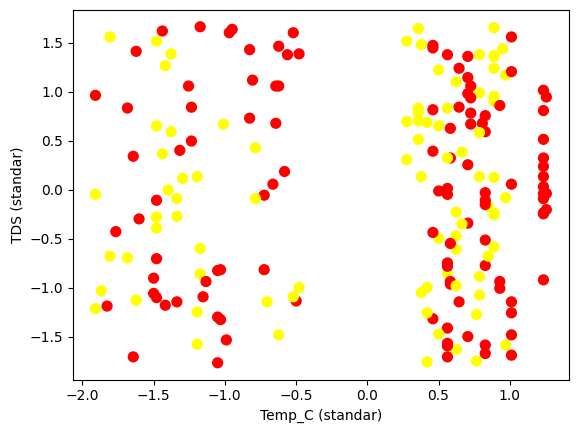

In [6]:
sample = df.sample(200, random_state=0)
X2 = StandardScaler().fit_transform(sample[['Temp_C', 'TDS']])
y2 = sample['Fase'].values

plt.scatter(X2[:, 0], X2[:, 1], c=y2, s=50, cmap='autumn')
plt.xlabel('Temp_C (standar)')
plt.ylabel('TDS (standar)')
plt.show()

### Langkah 3 & 4 [Ilustrasi Garis Pemisah dan Margin]

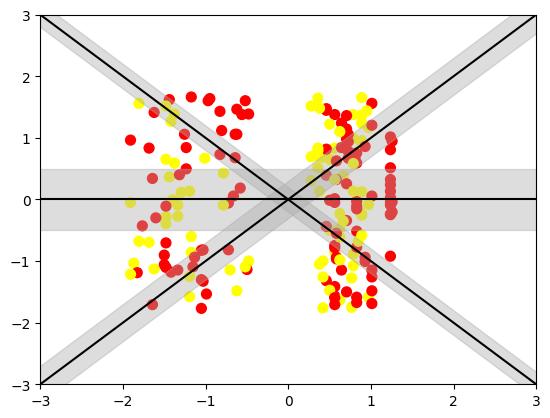

In [7]:
xfit = np.linspace(-3, 3)
plt.scatter(X2[:, 0], X2[:, 1], c=y2, s=50, cmap='autumn')

for m, b, d in [(1, 0, 0.3), (0, 0, 0.5), (-1, 0, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.show()

### Langkah 5 - Fitting Model (kernel linier)

In [8]:
model = SVC(kernel='linear', C=1)
model.fit(X2, y2)

SVC(C=1, kernel='linear')

Fungsi bantu untuk menampilkan decision boundary, margin, dan support vector:

In [9]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none', edgecolors='k')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

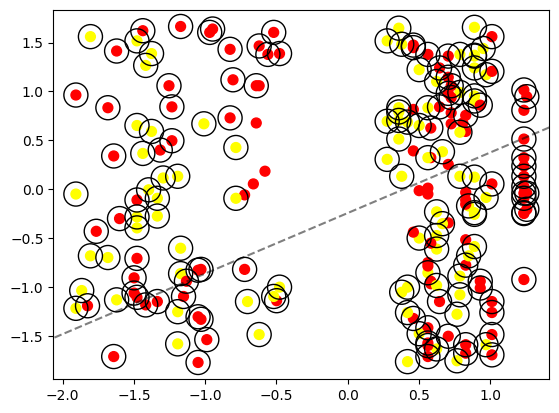

In [10]:
plt.scatter(X2[:, 0], X2[:, 1], c=y2, s=50, cmap='autumn')
plot_svc_decision_function(model)
plt.show()

In [11]:
print('Jumlah support vector:', len(model.support_vectors_))
model.support_vectors_[:5]

Jumlah support vector: 173


array([[ 1.236522  , -0.24648029],
       [-1.49950752, -0.90341532],
       [-1.33616247, -1.14544401],
       [-1.17281743,  1.66381761],
       [ 0.56272368, -1.56899422]])

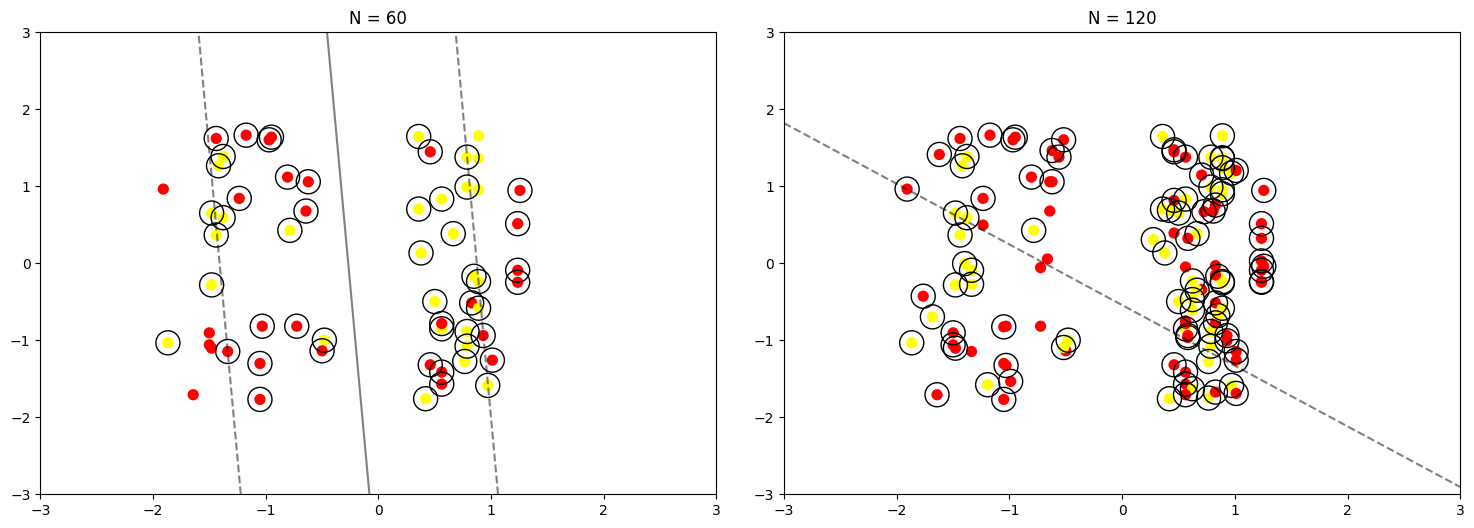

In [12]:
def plot_svm(N=10, ax=None):
    Xn, yn = X2[:N], y2[:N]
    model = SVC(kernel='linear', C=1)
    model.fit(Xn, yn)

    ax = ax or plt.gca()
    ax.scatter(Xn[:, 0], Xn[:, 1], c=yn, s=50, cmap='autumn')
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))
plt.show()

---
# Praktikum 2 [Klasifikasi SVM dengan Data Non Linier]

### Langkah 1 [Ilustrasi: kernel linier pada data yang tidak terpisah linier]

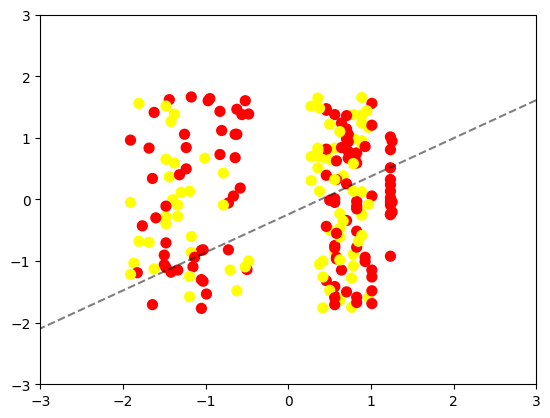

In [13]:
clf = SVC(kernel='linear').fit(X2, y2)

plt.scatter(X2[:, 0], X2[:, 1], c=y2, s=50, cmap='autumn')
plt.xlim(-3, 3); plt.ylim(-3, 3)
plot_svc_decision_function(clf, plot_support=False)
plt.show()

Proyeksi radial `r = exp(-(X**2).sum(1))` menambah dimensi ke-3 (versi statis, tanpa widget interaktif):

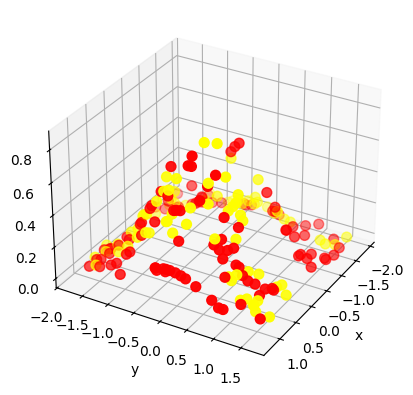

In [14]:
from mpl_toolkits import mplot3d

r = np.exp(-(X2 ** 2).sum(1))

ax = plt.subplot(projection='3d')
ax.scatter3D(X2[:, 0], X2[:, 1], r, c=y2, s=50, cmap='autumn')
ax.view_init(elev=30, azim=30)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('r')
plt.show()

### Langkah 2 - Fitting Model dengan Kernel RBF

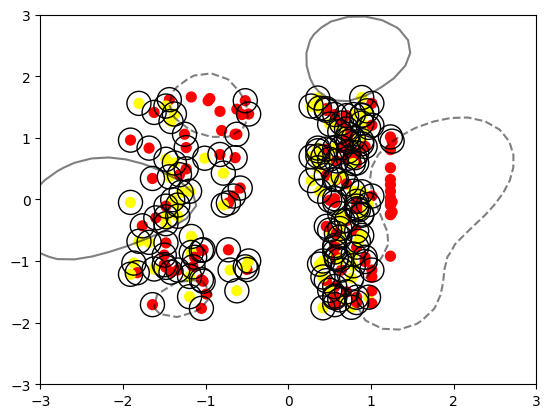

In [15]:
clf = SVC(kernel='rbf', C=1)
clf.fit(X2, y2)

plt.scatter(X2[:, 0], X2[:, 1], c=y2, s=50, cmap='autumn')
plt.xlim(-3, 3); plt.ylim(-3, 3)
plot_svc_decision_function(clf)
plt.show()

---
# Praktikum 3 [SVM pada Data Overlapping (Pengaruh Parameter C)]

### Langkah 3 - Analisis Dampak Tuning C

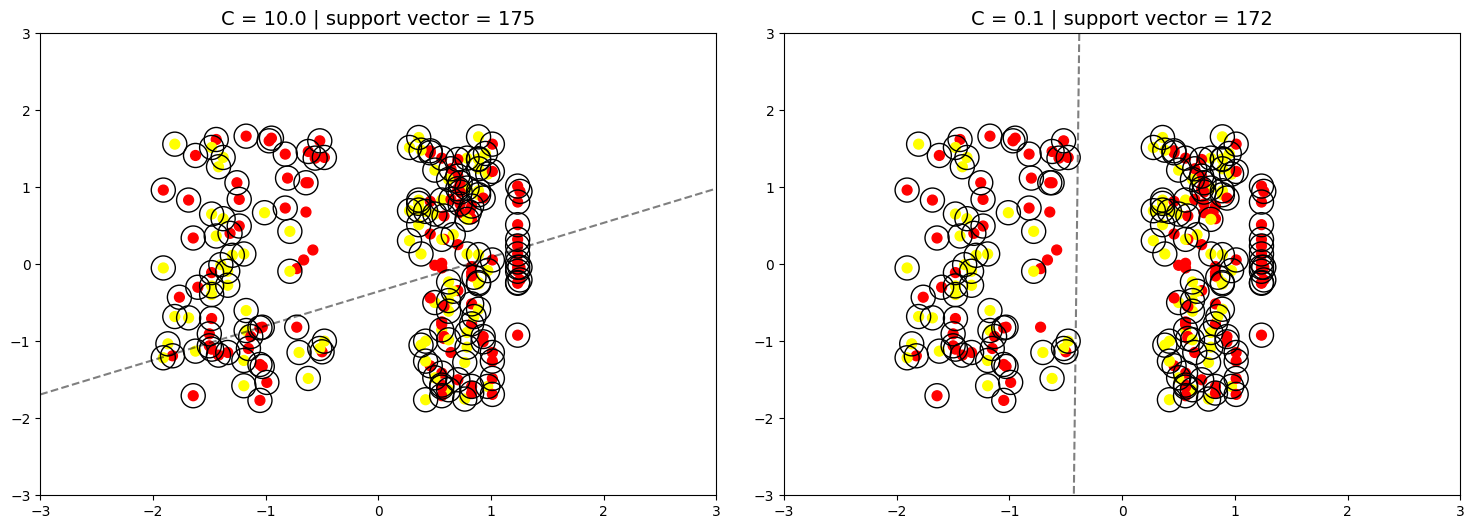

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X2, y2)
    axi.scatter(X2[:, 0], X2[:, 1], c=y2, s=50, cmap='autumn')
    axi.set_xlim(-3, 3); axi.set_ylim(-3, 3)
    plot_svc_decision_function(model, axi)
    axi.set_title('C = {0:.1f} | support vector = {1}'.format(C, len(model.support_vectors_)), size=14)
plt.show()

---
# Praktikum 4 [Pipeline, Split Data, dan Hyperparameter Tuning (GridSearch)


### Langkah 2 - Pra-Pengolahan (Pipeline)

In [17]:
scaler = StandardScaler()
svc = SVC(kernel='rbf', class_weight='balanced')
model = make_pipeline(scaler, svc)

### Langkah 3 - Split Data (80:20)

In [18]:
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2,
                                                random_state=42, stratify=y)
print(Xtrain.shape, Xtest.shape)

(1770, 4) (443, 4)


### Langkah 4 - Pembuatan Model + Tuning (GridSearchCV)

In [19]:
param_grid = {'svc__C': [0.1, 1, 5, 10, 50],
              'svc__gamma': [0.001, 0.01, 0.1, 1]}
grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

CPU times: user 14.2 s, sys: 18.4 ms, total: 14.2 s
Wall time: 16 s
{'svc__C': 50, 'svc__gamma': 0.1}
0.5559322033898305


In [20]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

### Langkah 6 - Cek Performansi

In [21]:
print(classification_report(ytest, yfit, target_names=['Fase Awal', 'Fase Akhir']))

              precision    recall  f1-score   support

   Fase Awal       0.56      0.46      0.50       235
  Fase Akhir       0.49      0.59      0.54       208

    accuracy                           0.52       443
   macro avg       0.52      0.52      0.52       443
weighted avg       0.53      0.52      0.52       443



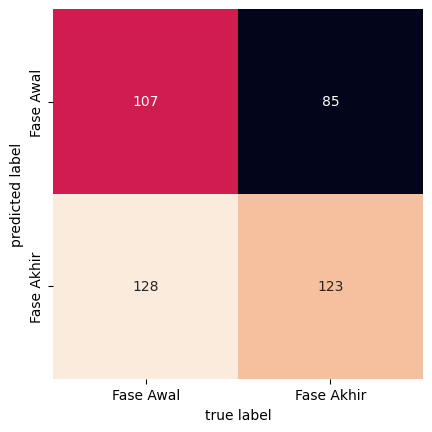

In [22]:
mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=['Fase Awal', 'Fase Akhir'],
            yticklabels=['Fase Awal', 'Fase Akhir'])
plt.xlabel('true label')
plt.ylabel('predicted label')
plt.show()

---
# Praktikum 5 — Klasifikasi Citra Siang dan Malam

---
# Tugas Praktikum

## Bagian 1 — SVM dengan Kernel Linear, Polynomial, RBF pada Split 70:30 dan 80:20

In [23]:
hasil = []

for test_size, nama_split in [(0.3, '70:30'), (0.2, '80:20')]:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=test_size,
                                          random_state=42, stratify=y)
    for kernel in ['linear', 'poly', 'rbf']:
        m = make_pipeline(StandardScaler(), SVC(kernel=kernel))
        m.fit(Xtr, ytr)
        acc_train = accuracy_score(ytr, m.predict(Xtr))
        acc_test = accuracy_score(yte, m.predict(Xte))
        hasil.append([nama_split, kernel, acc_train, acc_test])

tabel = pd.DataFrame(hasil, columns=['Split', 'Kernel', 'Akurasi Train', 'Akurasi Test'])
tabel

,Split,Kernel,Akurasi Train,Akurasi Test
0,70:30,linear,0.531311,0.531627
1,70:30,poly,0.563589,0.527108
2,70:30,rbf,0.595223,0.516566
3,80:20,linear,0.531638,0.530474
4,80:20,poly,0.555367,0.534989
5,80:20,rbf,0.600000,0.489842


In [24]:
# Tabel ringkas akurasi data uji (test)
tabel.pivot(index='Kernel', columns='Split', values='Akurasi Test')

Split,70:30,80:20
Kernel,,
linear,0.531627,0.530474
poly,0.527108,0.534989
rbf,0.516566,0.489842


## Bagian 2 — SVM Kernel RBF, Rasio 80:20, dengan Hyperparameter Tuning
(Pengganti klasifikasi siang/malam berbasis citra; dilakukan pada dataset selada.)

In [25]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2,
                                      random_state=42, stratify=y)

# 1) RBF default (sebelum tuning)
m_default = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
m_default.fit(Xtr, ytr)
acc_default = accuracy_score(yte, m_default.predict(Xte))
print(f'RBF default (C=1, gamma=scale) -> akurasi test: {acc_default:.4f}')

RBF default (C=1, gamma=scale) -> akurasi test: 0.4898


In [26]:
# 2) RBF dengan tuning C dan gamma (GridSearchCV, 5-fold)
param_grid = {'svc__C': [0.1, 1, 10, 100],
              'svc__gamma': [0.001, 0.01, 0.1, 1]}
grid = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel='rbf')),
                    param_grid, cv=5)
grid.fit(Xtr, ytr)

acc_tuned = accuracy_score(yte, grid.best_estimator_.predict(Xte))
print('Parameter terbaik :', grid.best_params_)
print(f'Akurasi CV terbaik : {grid.best_score_:.4f}')
print(f'Akurasi test (tuning): {acc_tuned:.4f}')

Parameter terbaik : {'svc__C': 10, 'svc__gamma': 1}
Akurasi CV terbaik : 0.5486
Akurasi test (tuning): 0.5440


In [27]:
# 3) Rekap hasil percobaan
pd.DataFrame({
    'Model': ['RBF default', 'RBF tuning (GridSearchCV)'],
    'Parameter': ['C=1, gamma=scale', str(grid.best_params_)],
    'Akurasi Test': [acc_default, acc_tuned]
})

,Model,Parameter,Akurasi Test
0,RBF default,"C=1, gamma=scale",0.489842
1,RBF tuning (GridSearchCV),"{'svc__C': 10, 'svc__gamma': 1}",0.544018


In [28]:
# (Opsional) lihat seluruh kombinasi C dan gamma yang dicoba
hasil_grid = pd.DataFrame(grid.cv_results_)[['param_svc__C', 'param_svc__gamma', 'mean_test_score']]
hasil_grid.pivot(index='param_svc__C', columns='param_svc__gamma', values='mean_test_score')

param_svc__gamma,0.001,0.010,0.100,1.000
param_svc__C,,,,
0.1,0.531638,0.531638,0.531638,0.531073
1.0,0.531638,0.531638,0.540113,0.540678
10.0,0.531638,0.519774,0.536158,0.548588
100.0,0.531638,0.527684,0.542938,0.537853
